In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from keras import callbacks

In [2]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [ ]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='binary_crossentropy', 
              metrics=[
                      tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                      tf.keras.metrics.Precision(name="precision"),
                      tf.keras.metrics.Recall(name="recall"),
                      tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
                      tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
                      tf.keras.metrics.AUC(curve="PR", name="pr_auc")
                  ])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)
test_loss, test_accuracy = model.evaluate(test_dataset)


Epoch 1/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 38s 587ms/step - accuracy: 0.5000 - loss: 266.6928 - val_accuracy: 0.4749 - val_loss: 0.6932
Epoch 2/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 35s 588ms/step - accuracy: 0.5021 - loss: 0.6931 - val_accuracy: 0.5251 - val_loss: 0.6930
Epoch 3/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 34s 558ms/step - accuracy: 0.5115 - loss: 0.6931 - val_accuracy: 0.5251 - val_loss: 0.6929
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 564ms/step - accuracy: 0.5142 - loss: 0.6930


In [4]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(16, kernel_size=3, 
                 activation='relu', 
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(32, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(64, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
        tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
results = model.evaluate(test_dataset, return_dict=True)
print(results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 210s 3s/step - accuracy: 0.7231 - f1: 0.7342 - loss: 0.6826 - pr_auc: 0.7352 - precision: 0.7212 - recall: 0.7477 - roc_auc: 0.7813 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 3.6766 - val_pr_auc: 0.5262 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5022
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 200s 3s/step - accuracy: 0.9441 - f1: 0.9460 - loss: 0.1543 - pr_auc: 0.9884 - precision: 0.9351 - recall: 0.9571 - roc_auc: 0.9875 - val_accuracy: 0.5356 - val_f1: 0.6934 - val_loss: 2.4979 - val_pr_auc: 0.6954 - val_precision: 0.5307 - val_recall: 1.0000 - val_roc_auc: 0.7577
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 205s 3s/step - accuracy: 0.9848 - f1: 0.9853 - loss: 0.0507 - pr_auc: 0.9989 - precision: 0.9808 - recall: 0.9898 - roc_auc: 0.9989 - val_accuracy: 0.6046 - val_f1: 0.7265 - val_loss: 1.4232 - val_pr_auc: 0.8554 - val_precision: 0.5705 - val_recall: 1.0000 - val_roc_auc: 0.9039
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - 

In [ ]:
model.save("../models/baseline_model.keras")

In [6]:
baseline_model = load_model("../models/baseline_model.keras")
baseline_model.summary()
model.count_params()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,413 (864.90 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 147,588 (576.52 KB)

73825

In [16]:
path = Path("../models/baseline_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 0.89 MB


In [15]:
print(train_dataset.class_names)

['flip', 'notflip']


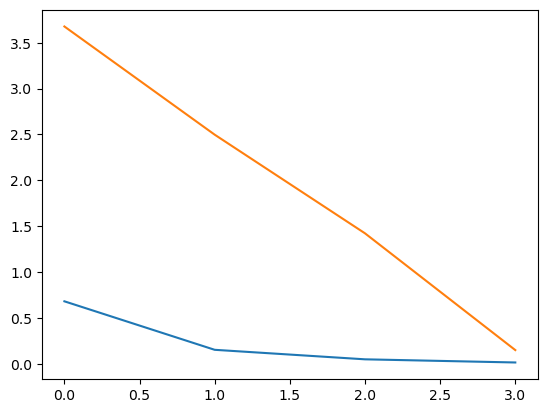

In [9]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [ ]:
resnet50_base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep its pretrained weights fixed
resnet50_base_model.trainable = False

resnet50_model = Sequential()
resnet50_model.add(Input(shape=(224, 224, 3)))
resnet50_model.add(tf.keras.layers.Lambda(preprocess_input))
resnet50_model.add(resnet50_base_model)
resnet50_model.add(GlobalAveragePooling2D())
resnet50_model.add(Dense(1, activation="sigmoid"))

resnet50_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

resnet50_model_history = resnet50_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

NameError: name 'base_model' is not defined

In [ ]:
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
print(resnet50_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 131s 7s/step - accuracy: 0.9631 - f1: 0.9647 - loss: 0.1461 - pr_auc: 0.9967 - precision: 0.9495 - recall: 0.9805 - roc_auc: 0.9965       
{'accuracy': 0.9631490707397461, 'f1': 0.9647434949874878, 'loss': 0.1461319476366043, 'pr_auc': 0.9966897964477539, 'precision': 0.9495267868041992, 'recall': 0.9804560542106628, 'roc_auc': 0.9964618682861328}


In [ ]:
resnet50_model.save("../models/resnet50_model.keras")

In [14]:
path = Path("../models/resnet50_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 90.63 MB


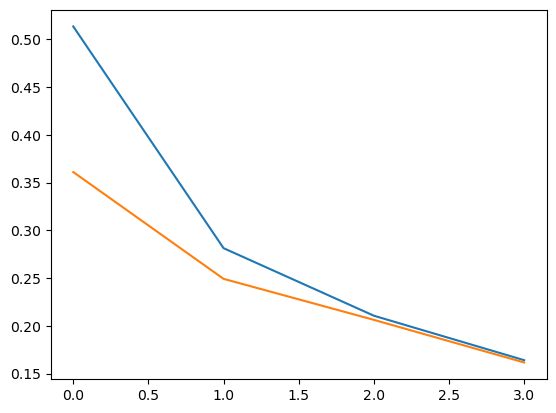

In [15]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base_model.trainable = False

vgg16_model = Sequential()
vgg16_model.add(Input(shape=(224, 224, 3)))
vgg16_model.add(tf.keras.layers.Lambda(preprocess_input))
vgg16_model.add(vgg16_base_model)
vgg16_model.add(GlobalAveragePooling2D())
vgg16_model.add(Dense(1, activation="sigmoid"))

vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_model_history = vgg16_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1966s 33s/step - accuracy: 0.5569 - f1: 0.5569 - loss: 1.1265 - pr_auc: 0.5797 - precision: 0.5701 - recall: 0.5444 - roc_auc: 0.5624 - val_accuracy: 0.6444 - val_f1: 0.6256 - val_loss: 0.7610 - val_pr_auc: 0.6772 - val_precision: 0.6995 - val_recall: 0.5657 - val_roc_auc: 0.6955
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 2101s 35s/step - accuracy: 0.7189 - f1: 0.7204 - loss: 0.6143 - pr_auc: 0.7653 - precision: 0.7333 - recall: 0.7079 - roc_auc: 0.7760 - val_accuracy: 0.8138 - val_f1: 0.8318 - val_loss: 0.4628 - val_pr_auc: 0.8630 - val_precision: 0.7914 - val_recall: 0.8765 - val_roc_auc: 0.8675
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1861s 31s/step - accuracy: 0.8166 - f1: 0.8225 - loss: 0.4243 - pr_auc: 0.8833 - precision: 0.8146 - recall: 0.8304 - roc_auc: 0.8873 - val_accuracy: 0.8766 - val_f1: 0.8889 - val_loss: 0.3317 - val_pr_auc: 0.9390 - val_precision: 0.8429 - val_recall: 0.9402 - val_roc_auc: 0.9381
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1796s 30s

NameError: name 'model' is not defined

In [10]:
vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 459s 24s/step - accuracy: 0.8660 - f1: 0.8662 - loss: 0.3194 - pr_auc: 0.9410 - precision: 0.8900 - recall: 0.8436 - roc_auc: 0.9429        
{'accuracy': 0.8659966588020325, 'f1': 0.8662206530570984, 'loss': 0.3193870782852173, 'pr_auc': 0.9409991502761841, 'precision': 0.8900343775749207, 'recall': 0.8436481952667236, 'roc_auc': 0.9429124593734741}


In [11]:
vgg16_model.save("../models/vgg16_model.keras")
path = Path("../models/vgg16_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 56.22 MB


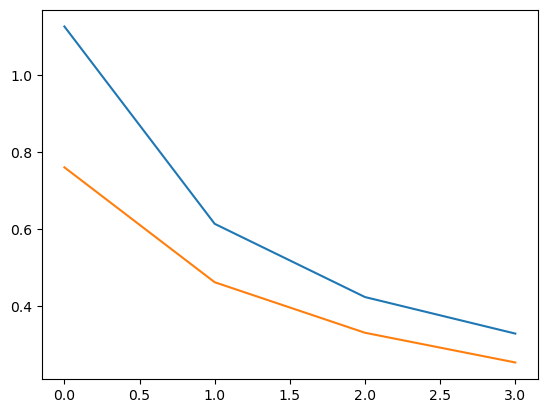

In [13]:
plt.plot(vgg16_model_history.history['loss'])
plt.plot(vgg16_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

augmentation_model = Sequential([
    #tf.keras.layers.RandomRotation(0.02),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

vgg16_base_model.trainable = False

vgg16_aug_model = Sequential()
vgg16_aug_model.add(Input(shape=(224, 224, 3)))
vgg16_aug_model.add(augmentation_model)
vgg16_aug_model.add(tf.keras.layers.Lambda(preprocess_input))
vgg16_aug_model.add(vgg16_base_model)
vgg16_aug_model.add(GlobalAveragePooling2D())
vgg16_aug_model.add(Dense(1, activation="sigmoid"))

vgg16_aug_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_aug_model_history = vgg16_aug_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_aug_model_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
print(vgg16_aug_model_results)

In [ ]:
vgg16_model.save("../models/vgg16_aug_model.keras")
path = Path("../models/vgg16_aug_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

In [16]:
efficientnetb0_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnetb0_base_model.trainable = False

efficientnetb0_model = Sequential()
efficientnetb0_model.add(Input(shape=(224, 224, 3)))
efficientnetb0_model.add(efficientnetb0_base_model)
efficientnetb0_model.add(GlobalAveragePooling2D())
efficientnetb0_model.add(Dense(1, activation="sigmoid"))

efficientnetb0_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
efficientnetb0_model_history = efficientnetb0_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
print(efficientnetb0_results)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 438s 7s/step - accuracy: 0.6661 - f1: 0.6918 - loss: 0.6136 - pr_auc: 0.7022 - precision: 0.6554 - recall: 0.7324 - roc_auc: 0.7316 - val_accuracy: 0.8347 - val_f1: 0.8597 - val_loss: 0.5104 - val_pr_auc: 0.8735 - val_precision: 0.7756 - val_recall: 0.9641 - val_roc_auc: 0.9047
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 352s 6s/step - accuracy: 0.8464 - f1: 0.8599 - loss: 0.4613 - pr_auc: 0.9126 - precision: 0.8061 - recall: 0.9213 - roc_auc: 0.9232 - val_accuracy: 0.8975 - val_f1: 0.9070 - val_loss: 0.4028 - val_pr_auc: 0.9654 - val_precision: 0.8659 - val_recall: 0.9522 - val_roc_auc: 0.9676
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.8887 - f1: 0.8972 - loss: 0.3808 - pr_auc: 0.9548 - precision: 0.8507 - recall: 0.9489 - roc_auc: 0.9570 - val_accuracy: 0.9079 - val_f1: 0.9179 - val_loss: 0.3394 - val_pr_auc: 0.9801 - val_precision: 0.8632 - val_recall: 0.9801 - val_roc_auc: 0.9791
E

In [17]:
efficientnetb0_model.save("../models/efficientnetb0_model.keras")
path = Path("../models/efficientnetb0_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 16.27 MB


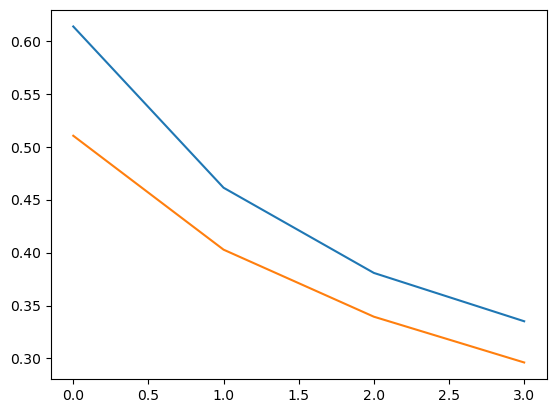

In [18]:
plt.plot(efficientnetb0_model_history.history['loss'])
plt.plot(efficientnetb0_model_history.history['val_loss'])

plt.show()

In [3]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = False

mobilenetv2_model = Sequential()
mobilenetv2_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_model.add(tf.keras.layers.Lambda(preprocess_input))
mobilenetv2_model.add(mobilenetv2_base_model)
mobilenetv2_model.add(GlobalAveragePooling2D())
mobilenetv2_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
mobilenetv2_model_history = mobilenetv2_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_results)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 304s 5s/step - accuracy: 0.7017 - f1: 0.7152 - loss: 0.5674 - pr_auc: 0.7785 - precision: 0.6988 - recall: 0.7324 - roc_auc: 0.7810 - val_accuracy: 0.7657 - val_f1: 0.7879 - val_loss: 0.4941 - val_pr_auc: 0.8830 - val_precision: 0.7509 - val_recall: 0.8287 - val_roc_auc: 0.8660
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 251s 4s/step - accuracy: 0.8333 - f1: 0.8429 - loss: 0.4206 - pr_auc: 0.9171 - precision: 0.8137 - recall: 0.8744 - roc_auc: 0.9165 - val_accuracy: 0.7929 - val_f1: 0.8278 - val_loss: 0.4298 - val_pr_auc: 0.9344 - val_precision: 0.7346 - val_recall: 0.9482 - val_roc_auc: 0.9232
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 242s 4s/step - accuracy: 0.8689 - f1: 0.8763 - loss: 0.3586 - pr_auc: 0.9445 - precision: 0.8467 - recall: 0.9081 - roc_auc: 0.9445 - val_accuracy: 0.8577 - val_f1: 0.8722 - val_loss: 0.3585 - val_pr_auc: 0.9555 - val_precision: 0.8256 - val_recall: 0.9243 - val_roc_auc: 0.9481
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 161s 3s/step -

In [4]:
mobilenetv2_model.save("../models/mobilenetv2_model.keras")
path = Path("../models/mobilenetv2_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 9.19 MB


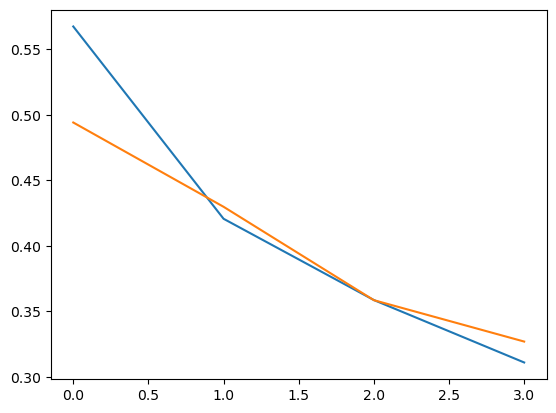

In [5]:
plt.plot(mobilenetv2_model_history.history['loss'])
plt.plot(mobilenetv2_model_history.history['val_loss'])

plt.show()

In [ ]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = True


for layer in mobilenetv2_base_model.layers[:-5]:
    layer.trainable = False


mobilenetv2_tuned_model = Sequential()
mobilenetv2_tuned_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_tuned_model.add(tf.keras.layers.Lambda(preprocess_input))
mobilenetv2_tuned_model.add(mobilenetv2_base_model)
mobilenetv2_tuned_model.add(GlobalAveragePooling2D())
mobilenetv2_tuned_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_tuned_model.compile(
    optimizer= tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

earlystopping = callbacks.EarlyStopping(monitor="val_loss",
                                        mode="min",
                                        patience=3,
                                        restore_best_weights=True)


mobilenetv2_tuned_model_history = mobilenetv2_tuned_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks = [earlystopping]

)

mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_results)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 330s 5s/step - accuracy: 0.5747 - f1: 0.3925 - loss: 0.6841 - pr_auc: 0.6853 - precision: 0.7285 - recall: 0.2686 - roc_auc: 0.6883 - val_accuracy: 0.6485 - val_f1: 0.5821 - val_loss: 0.6058 - val_pr_auc: 0.7809 - val_precision: 0.7748 - val_recall: 0.4661 - val_roc_auc: 0.7825
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 228s 3s/step - accuracy: 0.7973 - f1: 0.7840 - loss: 0.4800 - pr_auc: 0.8886 - precision: 0.8617 - recall: 0.7191 - roc_auc: 0.8963 - val_accuracy: 0.8138 - val_f1: 0.8258 - val_loss: 0.4674 - val_pr_auc: 0.9001 - val_precision: 0.8115 - val_recall: 0.8406 - val_roc_auc: 0.8975
Epoch 3/5
45/60 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step - accuracy: 0.8832 - f1: 0.8849 - loss: 0.3952 - pr_auc: 0.9492 - precision: 0.8896 - recall: 0.8804 - roc_auc: 0.9495

In [ ]:
mobilenetv2_model.save("../models/mobilenetv2_tuned_model.keras")
path = Path("../models/mobilenetv2_tuned_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 9.19 MB


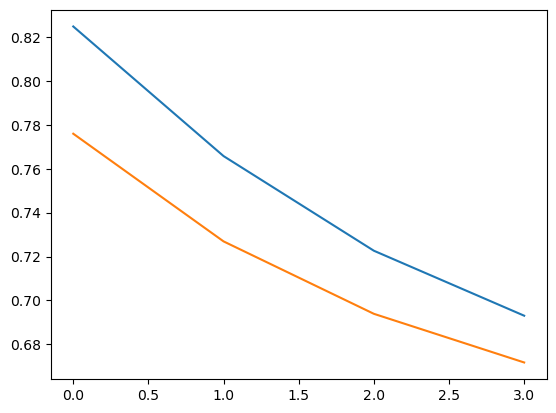

In [24]:
plt.plot(mobilenetv2_tuned_model_history.history['loss'])
plt.plot(mobilenetv2_tuned_model_history.history['val_loss'])

plt.show()